# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly, per the spec renumbering rule.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends of
its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we score a
candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal /
neural-crest FOXC and PRRX factors** (the Kürten lesson: widen beyond Snail/Zeb/Twist) — along
*this* trajectory (pSom body → neural-crest terminus), gated on detectable expression, and report
**where they actually sit** rather than forcing a root↔terminus pair.

The honest result (below): the EMT programme here is **root-loaded** — every sufficiently-expressed
factor leans toward the pSom-high developmental origin (mean_early ≥ mean_late), and the strongest
(ZEB2) concentrates at the root, with **no terminus EMT-TF**. This mirrors Qian 2020's root-loaded
finding, the opposite of Laughney's terminus-loaded lung case. Deliverable: `expression.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 11218 | pseudotime range 0.0 -> 8.97


### Derive the EMT-TF distribution along pseudotime (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3%
expression floor are too sparse to overlay (the Kürten detection-gate rule; only transcription
factors are in the panel — VIM and other non-TF mesenchymal markers are excluded by construction).

**Honest readout — the EMT programme is root-loaded.** *Every* sufficiently-expressed factor is
classified `EARLY(root)` by its own tercile means (mean_early ≥ mean_late), and the strongest
(**ZEB2**, ~24% detection) concentrates at the pSom-high origin. **There is no terminus EMT-TF**:
the least-root factor (FOXC2) is essentially flat. We therefore do **not** claim a root→terminus
EMT pair. The overlay contrasts the **most root-concentrated** factor (**ZEB2**) against the
**least-root / most body-distributed** expressed factor (**FOXC2**, which surfaced only because the
panel was widened to the FOXC/PRRX factors per the Kürten lesson) — showing that EMT-TF expression
concentrates toward the mesenchymal pSom origin, not that it spans a root→terminus axis.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
n_late = int((ok.end == 'LATE(terminus)').sum())
# root factor = most root-concentrated (min rho); body factor = least root (max rho)
root_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
body_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nexpressed EMT-TFs classified LATE(terminus): {n_late} of {len(ok)} '
      f'-> the EMT programme is {"root-loaded (no terminus factor)" if n_late==0 else "split"}')
print(f'root factor (min rho) = {root_tf}; least-root / body factor (max rho) = {body_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.238       0.181      0.108    -0.086    EARLY(root)
 FOXC1      0.083       0.059      0.031    -0.059    EARLY(root)
  ZEB1      0.059       0.033      0.023    -0.027    EARLY(root)
 FOXC2      0.122       0.072      0.051    -0.025    EARLY(root)
 SNAI1      0.030       0.022      0.015    -0.019    EARLY(root)
 PRRX1      0.003       0.002      0.001    -0.011    EARLY(root)
TWIST1      0.001       0.001      0.000    -0.008    EARLY(root)
 SNAI2      0.032       0.025      0.015    -0.006    EARLY(root)
TWIST2      0.001       0.000      0.000     0.007 LATE(terminus)
 PRRX2      0.001       0.000      0.001     0.020 LATE(terminus)

expressed EMT-TFs classified LATE(terminus): 0 of 5 -> the EMT programme is root-loaded (no terminus factor)
root factor (min rho) = ZEB2; least-root / body factor (max rho) = SNAI2


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Draw order is set by abundance
(the more widely-expressed factor first, the sparser one on top) so neither marker is fully
occluded. Each factor is thresholded at the upper quartile of expression among its expressing cells,
so only the strongest expressers show and the root (blue) / body (red) regions separate. This
categorical overlay of thresholded expressers on a grey manifold is the reference plotting style
(**not** a continuous single-gene colormap).

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.8, 'SNAI2': 0.789} | cells shown: {'ZEB2': 667, 'SNAI2': 91}
ZEB2: 23.8% expressing; 667 shown (upper quartile), mean pseudotime of shown cells = 0.37 (all cells = 0.49)
SNAI2: 3.2% expressing; 91 shown (upper quartile), mean pseudotime of shown cells = 0.35 (all cells = 0.49)
shown-cell pseudotime shift (SNAI2 body - ZEB2 root) = -0.01 (both root-biased; ZEB2 more so)
EMT programme is root-loaded: no terminus EMT-TF; expression concentrates toward the pSom origin
saved expression.pdf


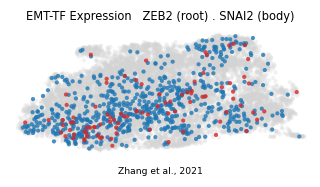

In [ ]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [root_tf, body_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [root_tf, body_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [root_tf, body_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [root_tf, body_tf]})
order = sorted([root_tf, body_tf], key=lambda g: -int(sel[g].sum()))
colors = {root_tf:'tab:blue', body_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {root_tf} (root) . {body_tf} (body)', size=7.5)
ax.text(.5, -.14, 'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [root_tf, body_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[body_tf]].mean() - tn[sel[root_tf]].mean()
print(f'shown-cell pseudotime shift ({body_tf} body - {root_tf} root) = {sep:+.2f} '
      f'(both root-biased; {root_tf} more so)')
print('EMT programme is root-loaded: no terminus EMT-TF; expression concentrates toward the pSom origin')
print('saved expression.pdf')